# Phân tích kết quả thực nghiệm K-Medoids

Notebook này đọc và phân tích kết quả đã lưu; không fit/chạy lại K-Medoids. Kết quả hiện có là từ thư viện `kmedoids`, so sánh hai cách tính khoảng cách Manhattan và Gower. Đây **không phải** so sánh bản tự cài đặt với thư viện.

`target` chỉ dùng để phân tích hậu nghiệm, không dùng tạo cụm.

## 1. Import thư viện và đường dẫn

Mặc định hình lưu vào `outputs/figures/`. Khi kiểm tra notebook, có thể đặt biến môi trường `KMEDOIDS_FIGURES_DIR` để ghi sang thư mục khác.

In [9]:
from pathlib import Path
import json
import os
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.data import CATEGORICAL_COLS, TARGET_COL
from src.evaluation import cluster_profile, posthoc_target_check

METRICS_DIR = ROOT / "outputs" / "metrics"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = Path(os.environ.get("KMEDOIDS_FIGURES_DIR", ROOT / "outputs" / "figures"))
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("Project root:", ROOT)
print("Figure output:", FIGURES_DIR)


Project root: c:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids
Figure output: c:\Users\havuh\OneDrive\Desktop\HocTap\Clustering_ of patients_with heart_disease_KMedoids\outputs\figures


## 2. Đọc file và kiểm tra tính nhất quán

Nh?n cụm, target, dữ liệu gốc đã xử lý và ma trận Manhattan phải cùng số dòng, cùng thứ tự. Chỉ số `medoid_index` bắt đầu từ 0 và trỏ tới đúng dòng trong `heart_dedup.csv`.

In [10]:
config = json.loads((METRICS_DIR / "run_config.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(METRICS_DIR / "k_selection.csv")
labels = pd.read_csv(METRICS_DIR / "labels.csv")
medoids = pd.read_csv(METRICS_DIR / "medoids.csv")
cross_method_ari = pd.read_csv(METRICS_DIR / "cross_method_ari.csv")
patients = pd.read_csv(PROCESSED_DIR / "heart_dedup.csv")
target = pd.read_csv(PROCESSED_DIR / "target.csv")[TARGET_COL]
X_manhattan = pd.read_csv(PROCESSED_DIR / "X_manhattan.csv")

n = int(config["n_rows"])
assert len(patients) == len(target) == len(labels) == len(X_manhattan) == n, (
    f"Row mismatch: config={n}, patients={len(patients)}, target={len(target)}, "
    f"labels={len(labels)}, X={len(X_manhattan)}"
)
assert patients[TARGET_COL].equals(target), "target.csv is not aligned with heart_dedup.csv"
assert TARGET_COL not in X_manhattan.columns, "target must not be a clustering feature"
assert medoids["medoid_index"].between(0, n - 1).all(), "Medoid index outside data rows"
assert set(metrics["distance"]) == {"manhattan", "gower"}

print(f"Verified {n:,} aligned rows; target is separate from clustering input.")
print("Source filter:", config.get("source_filter"), "| k range:", config["k_range"])
print("Backend: kmedoids library | method:", config["method"],
      "| init:", config["init"], "| seed:", config["random_state"])
print("Best k:", config["best_k"])


Verified 2,283 aligned rows; target is separate from clustering input.
Source filter: None | k range: [2, 3, 4, 5, 6, 7, 8]
Backend: kmedoids library | method: pam | init: build | seed: 42
Best k: {'manhattan': 2, 'gower': 3}


## 3. So sánh `k` và các chỉ số

Silhouette cao hơn thường cho thấy các cụm tách biệt/co cụm tốt hơn theo metric đang xét. Inertia là tổng khoảng cách tới medoid và thường giảm khi tăng `k`. **Không so trực tiếp trị số inertia giữa Manhattan và Gower** vì thang đo khác nhau.

,distance,k,silhouette,inertia,min_cluster_size,max_cluster_size,n_iter,ARI_target,purity_target,is_best_k
7,gower,2,0.189,435.111,665.0,1618.0,-1,0.035,0.596,False
8,gower,3,0.191,399.135,501.0,1173.0,-1,0.026,0.582,True
9,gower,4,0.177,371.822,370.0,728.0,-1,0.062,0.641,False
10,gower,5,0.171,349.066,338.0,659.0,-1,0.039,0.642,False
11,gower,6,0.170,331.357,293.0,496.0,-1,0.041,0.653,False
12,gower,7,0.162,318.941,189.0,416.0,-1,0.037,0.651,False
13,gower,8,0.171,307.384,112.0,401.0,-1,0.034,0.654,False
0,manhattan,2,0.157,15802.364,781.0,1502.0,-1,0.038,0.598,True
1,manhattan,3,0.102,14786.262,627.0,1022.0,-1,0.051,0.641,False
2,manhattan,4,0.098,14087.215,482.0,746.0,-1,0.038,0.625,False


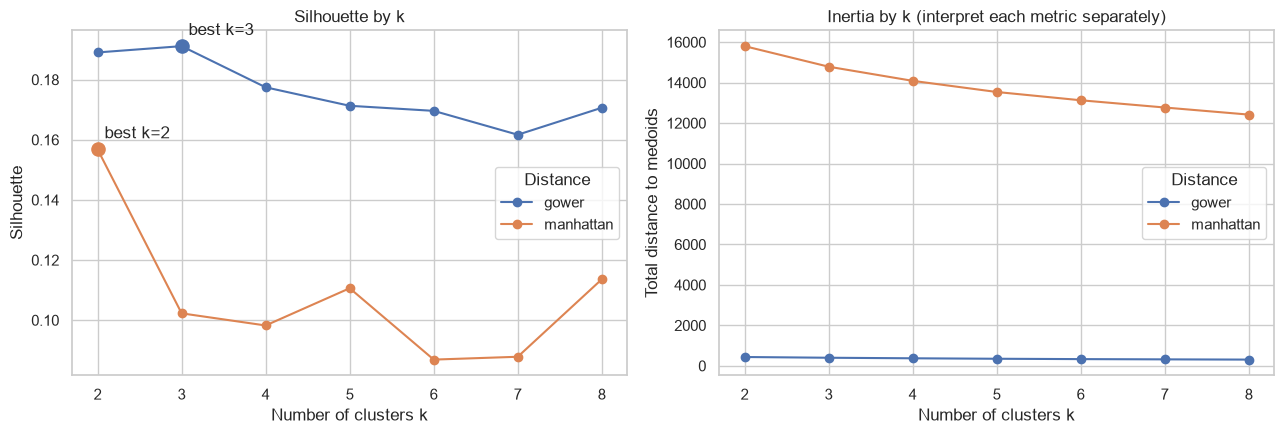

In [11]:
display(metrics.sort_values(["distance", "k"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for distance, group in metrics.groupby("distance"):
    group = group.sort_values("k")
    axes[0].plot(group["k"], group["silhouette"], marker="o", label=distance)
    axes[1].plot(group["k"], group["inertia"], marker="o", label=distance)
    best_k = int(config["best_k"][distance])
    best_row = group.loc[group["k"] == best_k].iloc[0]
    axes[0].scatter(best_k, best_row["silhouette"], s=90, zorder=3)
    axes[0].annotate(f"best k={best_k}", (best_k, best_row["silhouette"]),
                     xytext=(5, 8), textcoords="offset points")
axes[0].set(title="Silhouette by k", xlabel="Number of clusters k", ylabel="Silhouette")
axes[1].set(title="Inertia by k (interpret each metric separately)",
            xlabel="Number of clusters k", ylabel="Total distance to medoids")
for ax in axes:
    ax.legend(title="Distance")
    ax.set_xticks(sorted(metrics["k"].unique()))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_k_selection.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Kích thước cụm tại `k` được chọn

Xem quy mô và tỉ lệ từng cụm, kiểm tra cụm quá nhỏ hoặc phân bố mất cân bằng. Không kết luận chỉ dựa trên silhouette.

,distance,k,cluster,n,share
0,manhattan,2,0,1502,0.657906
1,manhattan,2,1,781,0.342094
2,gower,3,0,1173,0.513798
3,gower,3,1,609,0.266754
4,gower,3,2,501,0.219448


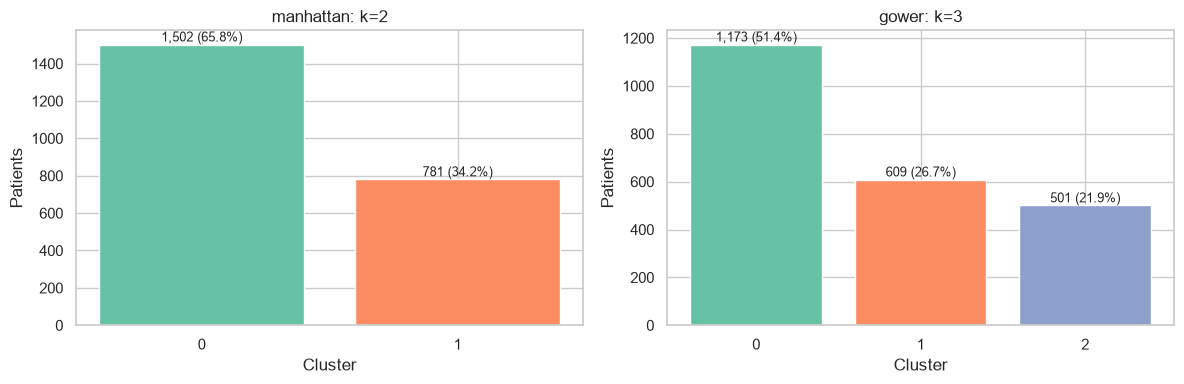

In [12]:
best_labels = {}
size_rows = []
for distance, best_k in config["best_k"].items():
    label_col = f"{distance}_k{best_k}"
    assert label_col in labels.columns, f"Missing label column: {label_col}"
    cluster_labels = labels[label_col].to_numpy()
    best_labels[distance] = (int(best_k), cluster_labels)
    counts = pd.Series(cluster_labels).value_counts().sort_index()
    for cluster_id, count in counts.items():
        size_rows.append({"distance": distance, "k": int(best_k),
                          "cluster": int(cluster_id), "n": int(count),
                          "share": float(count / n)})

cluster_sizes_best = pd.DataFrame(size_rows)
display(cluster_sizes_best)

fig, axes = plt.subplots(1, len(best_labels), figsize=(6 * len(best_labels), 4), squeeze=False)
for ax, (distance, (best_k, cluster_labels)) in zip(axes[0], best_labels.items()):
    counts = pd.Series(cluster_labels).value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values,
           color=sns.color_palette("Set2", len(counts)))
    ax.set(title=f"{distance}: k={best_k}", xlabel="Cluster", ylabel="Patients")
    for i, count in enumerate(counts.values):
        ax.text(i, count, f"{count:,} ({count/n:.1%})", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_cluster_sizes_best_k.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Manhattan và Gower có tạo cấu trúc cụm giống nhau không?

ARI đo mức độ tương đồng giữa hai cách chia cụm sau khi điều chỉnh cho kết quả ngẫu nhiên. ARI thấp không tự nó chứng minh mô hình nào sai; hai lần chạy này dùng metric khác nhau.

,k,ARI_manhattan_vs_gower
0,2,0.356
1,3,0.318
2,4,0.424
3,5,0.248
4,6,0.252
5,7,0.259
6,8,0.313


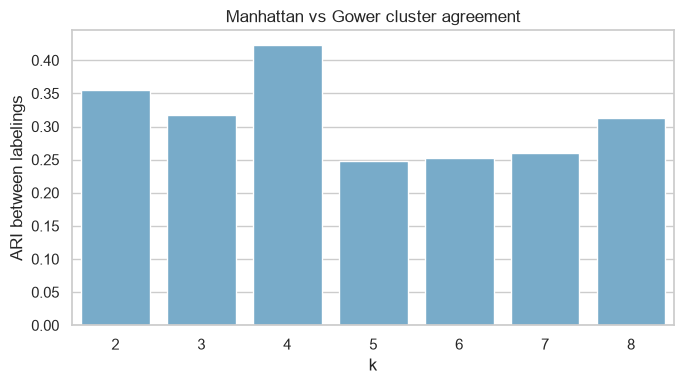

In [13]:
display(cross_method_ari.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cross_method_ari, x="k", y="ARI_manhattan_vs_gower",
            color="#6baed6", ax=ax)
ax.set(title="Manhattan vs Gower cluster agreement",
       xlabel="k", ylabel="ARI between labelings")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_manhattan_vs_gower_ari.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Hồ sơ các cụm

Thống kê dùng giá trị gốc đã tiền xử lý trong `heart_dedup.csv`, không dùng one-hot để diễn giải. `target_rate` là thông tin hậu nghiệm.

In [14]:
profiles = {}
categorical_shares = {}
for distance, (best_k, cluster_labels) in best_labels.items():
    profiles[distance] = cluster_profile(patients, cluster_labels)
    print(f"\n{distance.upper()} | k={best_k} | numeric and binary profile")
    display(profiles[distance])

    tmp = patients[CATEGORICAL_COLS].copy()
    tmp["cluster"] = cluster_labels
    categorical_shares[distance] = {}
    for col in CATEGORICAL_COLS:
        shares = pd.crosstab(tmp["cluster"], tmp[col], normalize="index").round(3)
        categorical_shares[distance][col] = shares
        print(f"\n{distance.upper()} | {col} proportions within cluster")
        display(shares)



MANHATTAN | k=2 | numeric and binary profile


,n,age,trestbps,chol,thalach,oldpeak,sex_rate,fbs_rate,exang_rate,target_rate
cluster,,,,,,,,,,
0,1502,51.61,128.60,242.50,148.90,0.43,0.722,0.156,0.158,0.452
1,781,57.57,137.98,248.01,126.81,1.69,0.823,0.224,0.707,0.695



MANHATTAN | cp proportions within cluster


cp,1,2,3,4
cluster,,,,
0,0.025,0.211,0.274,0.490
1,0.010,0.233,0.060,0.697



MANHATTAN | restecg proportions within cluster


restecg,0,1,2
cluster,,,
0,0.587,0.262,0.151
1,0.534,0.273,0.193


... (14 outputs left out)


GOWER | ca proportions within cluster


ca,0,1,2,3
cluster,,,,
0,0.904,0.053,0.026,0.017
1,0.862,0.072,0.044,0.021
2,0.892,0.052,0.042,0.014



GOWER | thal proportions within cluster


thal,3,6,7
cluster,,,
0,0.084,0.033,0.883
1,0.026,0.034,0.939
2,0.168,0.008,0.824


## 7. Đối chiếu `target` sau phân cụm

Bảng chéo, ARI và purity là đánh giá hậu nghiệm; `target` không tham gia fit. Phân cụm không giám sát không nhất thiết phải tái tạo nhãn chẩn đoán; cần nêu rõ giới hạn này khi viết kết luận.

In [15]:
posthoc_results = {}
for distance, (best_k, cluster_labels) in best_labels.items():
    check = posthoc_target_check(cluster_labels, target)
    posthoc_results[distance] = {"k": best_k, **check}
    counts = pd.crosstab(pd.Series(cluster_labels, name="cluster"),
                         target.rename(TARGET_COL), margins=True)
    shares = pd.crosstab(pd.Series(cluster_labels, name="cluster"),
                         target.rename(TARGET_COL), normalize="index")
    print(f"\n{distance.upper()} | k={best_k} | target counts by cluster")
    display(counts)
    print("Target proportions within each cluster:")
    display(shares.round(3))

display(pd.DataFrame(posthoc_results).T.rename_axis("distance"))



MANHATTAN | k=2 | target counts by cluster


target,0,1,All
cluster,,,
0,823,679,1502
1,238,543,781
All,1061,1222,2283


Target proportions within each cluster:


target,0,1
cluster,,
0,0.548,0.452
1,0.305,0.695



GOWER | k=3 | target counts by cluster


target,0,1,All
cluster,,,
0,595,578,1173
1,171,438,609
2,295,206,501
All,1061,1222,2283


Target proportions within each cluster:


target,0,1
cluster,,
0,0.507,0.493
1,0.281,0.719
2,0.589,0.411


,k,ARI,purity
distance,,,
manhattan,2.0,0.037825,0.598336
gower,3.0,0.026139,0.581691


## 8. Xem các medoid

Medoid là một mẫu bệnh nhân thật được chọn làm đại diện cụm theo tổng khoảng cách. Chỉ số `medoid_index` được đối chiếu với đúng dòng trong `heart_dedup.csv`. Cột `target` chỉ hiển để tham khảo hậu nghiệm.

In [16]:
selected_medoids = []
for distance, (best_k, _) in best_labels.items():
    subset = medoids[(medoids["distance"] == distance) & (medoids["k"] == best_k)]
    subset = subset.sort_values("cluster").reset_index(drop=True)
    medoid_records = patients.iloc[subset["medoid_index"].to_numpy()].reset_index(drop=True)
    selected_medoids.append(pd.concat([subset, medoid_records], axis=1))
selected_medoids = pd.concat(selected_medoids, ignore_index=True)
display(selected_medoids)


,distance,k,cluster,medoid_index,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang,target
0,manhattan,2,0,644,54,120.0,239.0,155.0,0.0,4,0,2,0,7,1.0,0,0,1
1,manhattan,2,1,1200,57,140.0,239.0,120.0,2.0,4,0,3,0,7,1.0,0,1,1
2,gower,3,0,833,50,130.0,218.0,143.0,0.5,4,0,2,0,7,1.0,0,0,1
3,gower,3,1,1335,58,137.0,232.0,124.0,1.4,4,1,3,0,7,1.0,0,1,1
4,gower,3,2,1788,51,130.0,256.0,149.0,0.5,4,0,2,0,7,0.0,0,0,1
